# Group XX - Machine Learning, Element 1: Apply dataset preparation mechanisms
| Item | Details |
|---|---|
| Group | **Group XX** |
| Members | **IGIHOZO Bienvenue** and **MUGISHA Aime Patrick** |
| Question | **Q2 - Next-day rain early warning for MINEMA district disaster offices (own scenario)** |
| Stage | **3 - Explore and audit the data (EDA)** |
| Driver / Navigator | Driver: MUGISHA Aime Patrick / Navigator: IGIHOZO Bienvenue |


## Stage 3 - Explore and audit the data (EDA) (PC 1.3)
We only **look** here; nothing is overwritten. Numeric copies are made only for the checks and charts.

In [1]:
import sys  # lets us tell Python where our own code (src/) is
from pathlib import Path  # file paths that work on every computer
import warnings  # hide harmless library notices
warnings.filterwarnings("ignore")  # keep output readable
import numpy as np  # maths on whole columns
import pandas as pd  # DataFrame tables
ROOT = Path.cwd().parent  # notebooks/ is inside q2_own_scenario
sys.path.insert(0, str(ROOT / "src"))  # make src/rain_pipeline.py importable
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)  # show all columns
RAW_DIR = ROOT / "data" / "raw" / "gsod"  # original NOAA files (never edited)
import rain_pipeline as rp  # our reusable functions

import matplotlib.pyplot as plt  # charts
import seaborn as sns  # statistical charts
sns.set_theme(style="whitegrid")  # chart style
FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)  # chart folder
raw = rp.load_raw(RAW_DIR)  # all values as text, exactly as in the files
raw.columns = raw.columns.str.strip()  # column names
txt = raw.apply(lambda s: s.str.strip())  # text without padding, for the checks only
num = lambda c: pd.to_numeric(txt[c], errors="coerce")  # helper: a column as numbers
print(raw.shape)  # size

(10614, 29)


### 3.1 Describe the dataset

In [2]:
print("Padded values, e.g.:", raw["TEMP"].head(3).tolist())  # numbers stored as text with spaces
numeric = pd.DataFrame({c: num(c) for c in rp.MISSING_CODES})  # numeric copy of the measured columns
numeric.describe().T.round(2)  # summary statistics - look at the max values

Padded values, e.g.: ['  70.0', '  71.8', '  68.2']


,count,mean,std,min,25%,50%,75%,max
TEMP,10614.0,70.79,2.90,58.1,68.9,70.9,72.8,83.10
DEWP,10614.0,84.18,491.40,39.6,58.1,60.6,62.5,9999.90
SLP,10614.0,9999.90,0.00,9999.9,9999.9,9999.9,9999.9,9999.90
STP,10614.0,976.42,55.39,839.7,999.9,999.9,999.9,999.90
VISIB,10614.0,8.86,52.77,2.4,6.0,6.2,6.2,999.90
WDSP,10614.0,11.13,88.87,0.0,1.5,3.5,4.5,999.90
MXSPD,10614.0,122.51,315.06,1.0,7.0,9.9,13.0,999.90
GUST,10614.0,958.59,196.56,13.0,999.9,999.9,999.9,999.90
MAX,10614.0,81.16,136.22,60.8,77.0,79.0,81.5,9999.90
MIN,10614.0,62.82,136.48,42.4,59.0,61.5,62.6,9999.90


**Reading the summary:** several maximums are exactly **9999.9, 999.9 or 99.99** - NOAA's codes for "not measured".
`SLP` and `SNDP` are the code in **every** row, and `GUST`/`STP` in most rows. Temperatures are in **Fahrenheit**
(about 58-83), wind in **knots**, visibility in **miles**, rain in **inches**.

In [3]:
for c in ["NAME", "PRCP_ATTRIBUTES", "FRSHTT"]:  # categorical / coded columns
    print(f"\n{c}:", txt[c].value_counts(dropna=False).head(10).to_dict())  # labels and counts


NAME: {'KIGALI INTERNATIONAL, RW': 3866, 'KAMEMBE, RW': 2835, 'GISENYI, RW': 2169, 'RUHENGERI, RW': 1744}

PRCP_ATTRIBUTES: {'G': 5203, 'I': 3827, '': 862, 'E': 318, 'A': 318, 'B': 69, 'H': 9, 'F': 6, 'C': 2}

FRSHTT: {'000000': 5164, '010010': 2211, '010000': 1562, '000010': 1187, '110010': 178, '100000': 142, '110000': 111, '100010': 26, '010110': 12, '011010': 7}


### 3.2 Missing values (true and disguised), duplicates

In [4]:
codes = pd.Series({c: int((numeric[c] == code).sum()) for c, code in rp.MISSING_CODES.items()})  # disguised missing
empty = txt.eq("").sum()  # empty strings
miss = pd.DataFrame({"missing_code": codes, "pct": (codes / len(raw) * 100).round(1)}).sort_values("missing_code", ascending=False)  # table
print("Empty cells per column (only flags):", empty[empty > 0].to_dict())  # e.g. PRCP_ATTRIBUTES
print("Duplicated station-days:", txt.duplicated(subset=["STATION", "DATE"]).sum())  # duplicates
miss  # disguised missing per column

Empty cells per column (only flags): {'MAX_ATTRIBUTES': 6662, 'MIN_ATTRIBUTES': 5855, 'PRCP_ATTRIBUTES': 862}
Duplicated station-days: 0


,missing_code,pct
SLP,10614,100.0
SNDP,10614,100.0
GUST,10165,95.8
STP,8997,84.8
MXSPD,1212,11.4
PRCP,862,8.1
WDSP,85,0.8
VISIB,30,0.3
DEWP,26,0.2
MIN,2,0.0


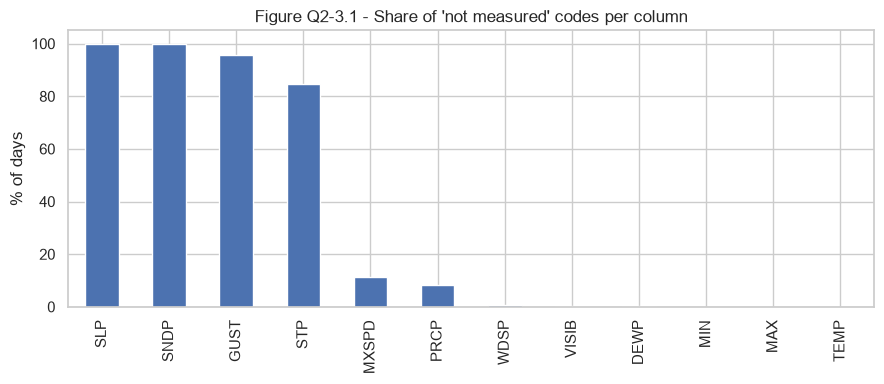

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))  # empty chart
miss["pct"].plot.bar(ax=ax, color="#4C72B0")  # % missing per column
ax.set_ylabel("% of days"); ax.set_title("Figure Q2-3.1 - Share of 'not measured' codes per column")  # labels
plt.tight_layout(); plt.savefig(FIG / "q2_fig3_1_missing.png", dpi=120); plt.show()  # save and display

**Interpretation:** `SLP` and `SNDP` are 100 % missing, `GUST` 96 % and `STP` 85 % - these columns cannot be used.
`MXSPD` (11 %) and `PRCP` (8 %) need imputation; the other columns are almost complete. No station-day is duplicated.

### 3.3 Missing DAYS (gaps in the calendar)

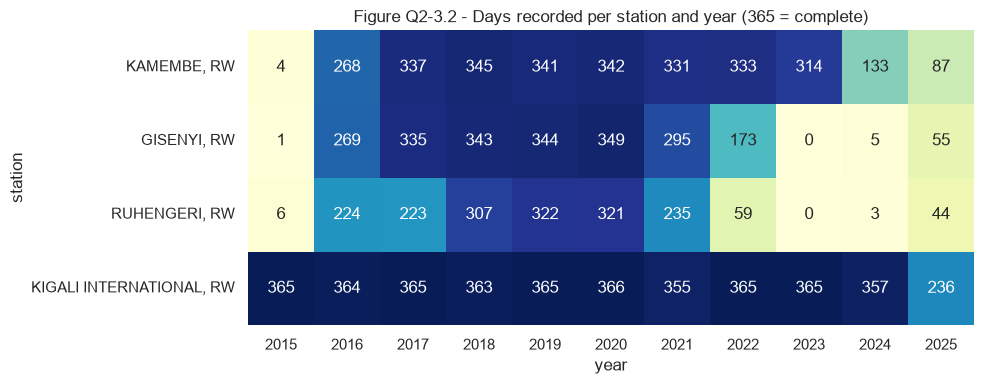

In [6]:
dates = pd.to_datetime(txt["DATE"])  # dates
cov = (pd.DataFrame({"station": txt["NAME"], "year": dates.dt.year}).value_counts().unstack(0).fillna(0).astype(int))  # days per station-year
fig, ax = plt.subplots(figsize=(10, 4))  # chart
sns.heatmap(cov.T, annot=True, fmt="d", cmap="YlGnBu", ax=ax, cbar=False)  # days recorded per year (max 365)
ax.set_title("Figure Q2-3.2 - Days recorded per station and year (365 = complete)")  # title
plt.tight_layout(); plt.savefig(FIG / "q2_fig3_2_coverage.png", dpi=120); plt.show()  # save and display

**Interpretation:** Kigali is almost complete, but Gisenyi and Ruhengeri miss large parts of several years (and all of 2023),
and 2025 stops in August. Missing days mean "tomorrow" is sometimes unknown, and stations are **not equally represented**.

### 3.4 Outliers and unrealistic values

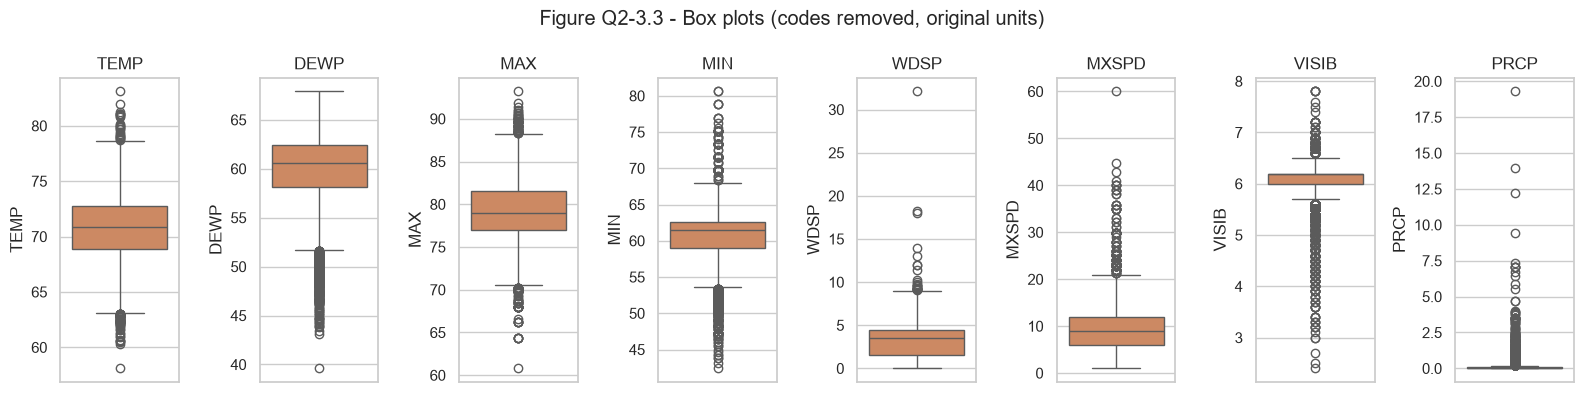

In [7]:
valid = numeric.mask(numeric.isin([9999.9, 999.9, 99.99]))  # hide the codes to see the real values
cols = ["TEMP", "DEWP", "MAX", "MIN", "WDSP", "MXSPD", "VISIB", "PRCP"]  # measured columns
fig, axes = plt.subplots(1, len(cols), figsize=(16, 4))  # one box per column
for ax, c in zip(axes, cols):  # draw each
    sns.boxplot(y=valid[c], ax=ax, color="#DD8452"); ax.set_title(c)  # box plot
fig.suptitle("Figure Q2-3.3 - Box plots (codes removed, original units)"); plt.tight_layout()  # title
plt.savefig(FIG / "q2_fig3_3_boxplots.png", dpi=120); plt.show()  # save and display

In [8]:
def iqr(s):  # IQR rule
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1  # quartiles and range
    return pd.Series({"lower": q1 - 1.5 * i, "upper": q3 + 1.5 * i, "n_outliers": int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())})  # result
out = valid[cols].apply(iqr).T.round(2)  # apply to each column
out["max"] = valid[cols].max().round(2)  # largest value for comparison
out  # table

,lower,upper,n_outliers,max
TEMP,63.05,78.65,87.0,83.10
DEWP,51.65,68.85,434.0,67.90
MAX,70.25,88.25,168.0,93.20
MIN,53.60,68.00,753.0,80.60
WDSP,-3.00,9.00,24.0,32.10
MXSPD,-3.00,21.00,134.0,60.00
VISIB,5.70,6.50,1612.0,7.80
PRCP,-0.12,0.20,1592.0,19.29


**Interpretation:** most IQR "outliers" are real weather (heavy-rain days, windy days) and are **kept**. Two values are not
credible: a daily **mean** wind of about 32 knots (59 km/h) and a max sustained wind of 60 knots (111 km/h) - both are
set to missing in Stage 4. Rain amounts are very right-skewed (most days 0, a few days > 1 inch) -> log transform later.

### 3.5 Consistency checks and the precipitation problem

In [9]:
dew_gt = (valid["DEWP"] > valid["TEMP"] + 1).sum()  # dew point above temperature (impossible)
max_lt = (valid["MAX"] < valid["MIN"]).sum()  # max below min (impossible)
rain_flag = txt["FRSHTT"].str.zfill(6).str[1].astype(int)  # rain observed (1/0)
p = valid["PRCP"]  # rain amount (inches)
incomplete = txt["PRCP_ATTRIBUTES"] == "I"  # incomplete totals
print("Dew point > temperature:", dew_gt, "| max < min:", max_lt)  # impossible combinations
print("PRCP flagged 'I' (incomplete):", incomplete.sum(), f"({incomplete.mean():.0%})")  # how many
print("Rain observed but PRCP = 0:", ((rain_flag == 1) & (p == 0)).sum())  # contradiction
print("Rain observed but PRCP = 0 AND flag I:", ((rain_flag == 1) & (p == 0) & incomplete).sum())  # explained by I
pd.crosstab(rain_flag.rename("rain flag"), pd.cut(p, [-0.1, 0, 0.1, 10], labels=["0", "0-0.1 in", ">0.1 in"]).rename("PRCP"))  # table

Dew point > temperature: 0 | max < min: 0
PRCP flagged 'I' (incomplete): 3827 (36%)
Rain observed but PRCP = 0: 903
Rain observed but PRCP = 0 AND flag I: 0


PRCP,0,0-0.1 in,>0.1 in
rain flag,,,
0,4900,661,961
1,903,883,1441


**Finding:** the rain **flag** and the rain **amount** often disagree - 903 days say "rain observed" with 0.00 inch, and
961 days have more than 0.1 inch with no rain flag. They are recorded differently: the flag comes from the weather seen
during the reported hours, while the amount is a 24-hour total that can cover the previous night, and 36 % of totals are
also marked **incomplete ('I')**. We build the **target from the rain flag** because it is recorded every day (never
coded missing) and describes rain seen at the station - the event MINEMA warns about. The amount is kept only as a
feature with a `prcp_incomplete` indicator, and the disagreement is reported as a limitation.

### 3.6 The target and relationships

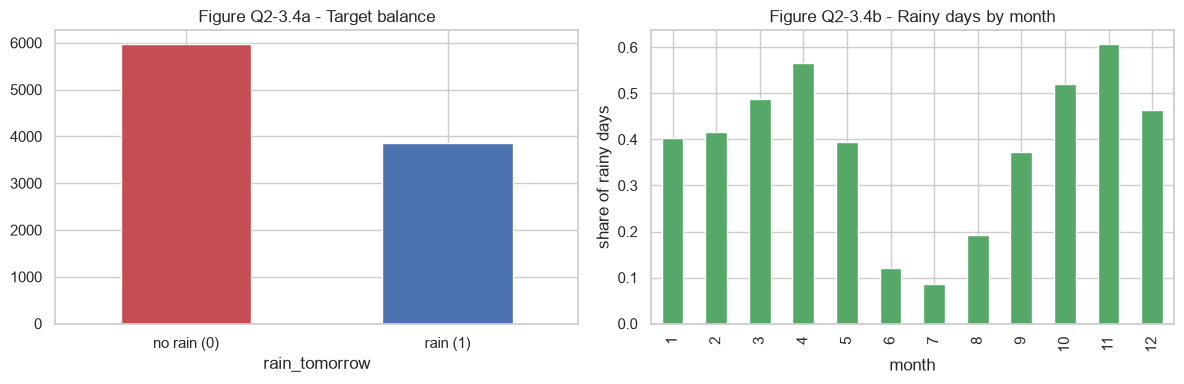

Share rain_tomorrow = 1: 0.392


In [10]:
d = pd.DataFrame({"station": txt["NAME"].str.replace(", RW", "").str.title(), "date": dates, "rain": rain_flag}).sort_values(["station", "date"])  # small table
d["rain_tomorrow"] = d.groupby("station")["rain"].shift(-1).where(d.groupby("station")["date"].shift(-1) - d["date"] == pd.Timedelta(days=1))  # preview of target
fig, axes = plt.subplots(1, 2, figsize=(12, 4))  # two charts
d["rain_tomorrow"].value_counts().sort_index().plot.bar(ax=axes[0], color=["#C44E52", "#4C72B0"])  # class balance
axes[0].set_xticklabels(["no rain (0)", "rain (1)"], rotation=0); axes[0].set_title("Figure Q2-3.4a - Target balance")  # labels
d.groupby(d["date"].dt.month)["rain"].mean().plot.bar(ax=axes[1], color="#55A868")  # rain frequency by month
axes[1].set_xlabel("month"); axes[1].set_ylabel("share of rainy days"); axes[1].set_title("Figure Q2-3.4b - Rainy days by month")  # labels
plt.tight_layout(); plt.savefig(FIG / "q2_fig3_4_target.png", dpi=120); plt.show()  # save and display
print("Share rain_tomorrow = 1:", round(d["rain_tomorrow"].mean(), 3))  # balance

**Interpretation:** about 39 % of days are followed by a rainy day - **moderately imbalanced** (no resampling needed;
class weights are an option). Rain follows Rwanda's seasons clearly: the long rains (March-May) and short rains
(September-December) are wet, June-August is dry - so **season/month** is an important feature.

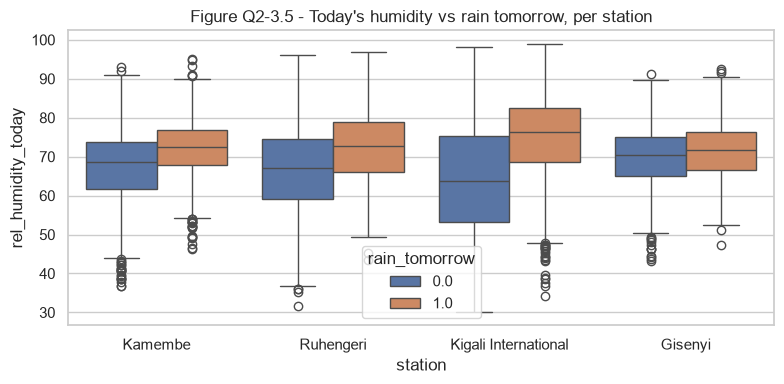

In [11]:
t = (valid["TEMP"] - 32) * 5 / 9; dp = (valid["DEWP"] - 32) * 5 / 9  # quick Celsius copies for the chart
rh = 100 * np.exp(17.625 * dp / (243.04 + dp)) / np.exp(17.625 * t / (243.04 + t))  # relative humidity
plot = pd.DataFrame({"rel_humidity_today": rh, "station": d.sort_index()["station"], "rain_tomorrow": d.sort_index()["rain_tomorrow"]}).dropna()  # table
fig, ax = plt.subplots(figsize=(8, 4))  # chart
sns.boxplot(data=plot, x="station", y="rel_humidity_today", hue="rain_tomorrow", ax=ax)  # humidity today vs rain tomorrow
ax.set_title("Figure Q2-3.5 - Today's humidity vs rain tomorrow, per station")  # title
plt.tight_layout(); plt.savefig(FIG / "q2_fig3_5_humidity.png", dpi=120); plt.show()  # save and display

**Interpretation:** at every station, days followed by rain have **higher humidity today** - a useful signal. Kigali is
drier overall, so the station must stay in the data.

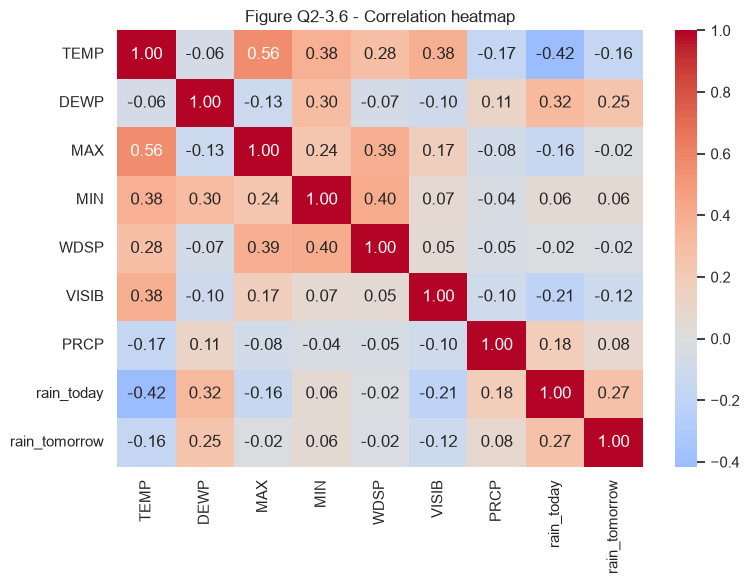

In [12]:
corr = pd.DataFrame({"TEMP": valid.TEMP, "DEWP": valid.DEWP, "MAX": valid.MAX, "MIN": valid.MIN, "WDSP": valid.WDSP,
                     "VISIB": valid.VISIB, "PRCP": valid.PRCP, "rain_today": rain_flag,
                     "rain_tomorrow": d.sort_index()["rain_tomorrow"]}).corr()  # correlation matrix
fig, ax = plt.subplots(figsize=(8, 6))  # chart
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)  # heatmap
ax.set_title("Figure Q2-3.6 - Correlation heatmap"); plt.tight_layout()  # title
plt.savefig(FIG / "q2_fig3_6_corr.png", dpi=120); plt.show()  # save and display

**Interpretation:** rain **today** and the dew point are the clearest single signals for rain tomorrow; mean, max and min
temperature are strongly related to each other (redundant information). **Leakage risk:** any value from tomorrow
(e.g. tomorrow's PRCP or FRSHTT) must never be a feature, and the split must follow time.

### 3.7 Data Quality Report - saved to `docs/data_quality_report.csv`

In [13]:
gaps = int(d.groupby("station")["date"].diff().dt.days.gt(1).sum())  # number of breaks in the calendar
dqr = pd.DataFrame([  # problem, columns, records, severity, treatment
    (1, "Numbers and dates stored as padded text ('  70.0')", "all", int((raw["TEMP"].str.len() != raw["TEMP"].str.strip().str.len()).sum()), "Medium", "strip spaces, convert to float/datetime"),
    (2, "Disguised missing codes 9999.9 / 999.9 / 99.99", ", ".join(codes[codes > 0].index), int(codes.sum()), "High", "replace by NaN"),
    (3, "Columns (almost) completely empty", "SLP, SNDP, GUST, STP", int(codes[["SLP", "SNDP", "GUST", "STP"]].min()), "Medium", "drop columns > 50 % missing"),
    (4, "Imperial units (F, knots, miles, inches)", "TEMP, DEWP, MAX, MIN, WDSP, MXSPD, VISIB, PRCP", len(raw), "Medium", "convert to C, km/h, km, mm"),
    (5, "Several facts packed in one code (FRSHTT '010010')", "FRSHTT", len(raw), "Medium", "split into fog/rain/hail/thunder 0/1"),
    (6, "Incomplete precipitation totals (flag I)", "PRCP, PRCP_ATTRIBUTES", int(incomplete.sum()), "High", "do not use PRCP as target; keep prcp_incomplete flag"),
    (7, "Rain flag and rain amount disagree (flag 1 & 0 in, or flag 0 & > 0.1 in)", "PRCP vs FRSHTT",
     int(((rain_flag == 1) & (p == 0)).sum() + ((rain_flag == 0) & (p > 0.1)).sum()), "High", "target from rain flag; report as limitation"),
    (8, "Missing days / station-years (gaps)", "DATE", gaps, "High", "target only when next day exists; lags only over consecutive days"),
    (9, "Unequal station coverage", "NAME", int(cov.sum().max() - cov.sum().min()), "Low", "keep station as a feature; report bias"),
    (10, "Unrealistic wind values", "WDSP, MXSPD", int((valid.WDSP > 21.6).sum() + (valid.MXSPD > 48.6).sum()), "Low", "set to NaN"),
    (11, "Skewed rain amount", "PRCP", int((valid.PRCP > 0).sum()), "Low", "log(1 + mm) feature"),
    (12, "Leakage risk: target comes from tomorrow; random split would mix future into training", "rain_tomorrow, DATE", len(raw), "High", "only today/past features; chronological split"),
    (13, "Long station names with country suffix", "NAME", len(raw), "Low", "short station + district + province"),
], columns=["no", "problem", "columns", "records_affected", "severity", "proposed_treatment"])
dqr.to_csv(ROOT / "docs" / "data_quality_report.csv", index=False)  # save
dqr  # display (13 kinds of problems)

,no,problem,columns,records_affected,severity,proposed_treatment
0,1,Numbers and dates stored as padded text (' 70...,all,10614,Medium,"strip spaces, convert to float/datetime"
1,2,Disguised missing codes 9999.9 / 999.9 / 99.99,"DEWP, SLP, STP, VISIB, WDSP, MXSPD, GUST, MAX,...",42609,High,replace by NaN
2,3,Columns (almost) completely empty,"SLP, SNDP, GUST, STP",8997,Medium,drop columns > 50 % missing
3,4,"Imperial units (F, knots, miles, inches)","TEMP, DEWP, MAX, MIN, WDSP, MXSPD, VISIB, PRCP",10614,Medium,"convert to C, km/h, km, mm"
4,5,Several facts packed in one code (FRSHTT '0100...,FRSHTT,10614,Medium,split into fog/rain/hail/thunder 0/1
5,6,Incomplete precipitation totals (flag I),"PRCP, PRCP_ATTRIBUTES",3827,High,do not use PRCP as target; keep prcp_incomplet...
6,7,Rain flag and rain amount disagree (flag 1 & 0...,PRCP vs FRSHTT,1864,High,target from rain flag; report as limitation
7,8,Missing days / station-years (gaps),DATE,792,High,target only when next day exists; lags only ov...
8,9,Unequal station coverage,NAME,2122,Low,keep station as a feature; report bias
9,10,Unrealistic wind values,"WDSP, MXSPD",2,Low,set to NaN


**Checkpoint answer - two problems and why they matter**
1. **Incomplete precipitation (flag I):** a day with "0 inches" may really have been rainy; a target built from PRCP would
   teach the model wrong answers. We use the observed rain flag instead.
2. **Time leakage:** with a random split, days from 2025 would train a model tested on 2017 - it would look better than it
   can ever be in real use. We split by time.